# Phase 1: Core Engine - Comparing Tokenizers

**Goal:** take any text and print tokens, IDs and counts for tokenizers from *different families*, in one table.

**Design idea:** every tokenizer (tiktoken, Hugging Face, my own BPE) is wrapped in a small adapter with the same method, `encode(text) -> list[Token]`. The comparison code never needs to know which library is underneath. This is the interface the web app will use in Phase 2.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from bpe import BPETokenizer
from tokenizer_engine import (MyBPETokenizer, default_registry, load_tokenizers,
                              compare, add_ratio_vs)
import tiktoken
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

import warnings
warnings.filterwarnings('ignore')

## 1. Load the tokenizers
Each one loads separately. If one fails (no internet, a gated model, a missing library) the others still work, and the failure is printed instead of crashing the notebook.

I also add **my own BPE from Phase 0**, trained on a small English text, as a baseline to compare against the real ones.

In [2]:
PHASE0_TEXT = """Tokenization turns text into tokens. A tokenizer splits text into subword tokens,
and each token has an id. Language models read token ids, not words. The tokenizer learns
frequent pieces such as ing, tion, the and token from a training corpus.
Lower, lowest, newer and newest share the pieces low, new, er and est.
""" * 10

registry = default_registry() + [
    ("my-bpe (Phase 0)", lambda: MyBPETokenizer(BPETokenizer().train(PHASE0_TEXT, vocab_size=300))),
]
tokenizers, failures = load_tokenizers(registry)
print(f"\n{len(tokenizers)} loaded, {len(failures)} failed")

[ok]     gpt-3.5/4 (cl100k)
[ok]     gpt-4o (o200k)
[ok]     gpt2
[ok]     bert-base-uncased
[ok]     t5-small
[ok]     my-bpe (Phase 0)

6 loaded, 0 failed


## 2. Look inside one tokenizer
Every token has an **id**, its **piece** (how the vocabulary spells it), and the **text** it covers with character offsets. Different families spell pieces differently: `Ġ` (GPT-2) and `▁` (T5) both mean "a space came before this", and `##` (BERT) means "continues the previous word".

In [3]:
def show(tokenizer, text, limit=30):
    """Token table for one tokenizer (first `limit` tokens)."""
    toks = tokenizer.encode(text)
    df = pd.DataFrame([vars(t) for t in toks[:limit]])
    print(f"{tokenizer.name}  |  {tokenizer.family}, {tokenizer.algorithm}  |  {len(toks)} tokens")
    return df

sentence = "Tokenization is unbelievable!"
for t in tokenizers:
    display(show(t, sentence))

gpt-3.5/4 (cl100k)  |  OpenAI, byte-level BPE  |  5 tokens


,id,piece,text,start,end
0,3404,Token,Token,0,5
1,2065,ization,ization,5,12
2,374,is,is,12,15
3,52229,unbelievable,unbelievable,15,28
4,0,!,!,28,29


gpt-4o (o200k)  |  OpenAI, byte-level BPE  |  5 tokens


,id,piece,text,start,end
0,4421,Token,Token,0,5
1,2860,ization,ization,5,12
2,382,is,is,12,15
3,83614,unbelievable,unbelievable,15,28
4,0,!,!,28,29


gpt2  |  OpenAI (old), byte-level BPE  |  5 tokens


,id,piece,text,start,end
0,30642,Token,Token,0,5
1,1634,ization,ization,5,12
2,318,Ġis,is,12,15
3,24479,Ġunbelievable,unbelievable,15,28
4,0,!,!,28,29


... (2 outputs left out)

t5-small  |  Google T5, Unigram (SentencePiece)  |  6 tokens


,id,piece,text,start,end
0,304,▁To,To,0,2
1,2217,ken,ken,2,5
2,1707,ization,ization,5,12
3,19,▁is,is,13,15
4,25525,▁unbelievable,unbelievable,16,28
5,55,!,!,28,29


my-bpe (Phase 0)  |  Mine, byte-level BPE  |  23 tokens


,id,piece,text,start,end
0,84,T,T,0,1
1,259,oken,oken,1,5
2,272,iz,iz,5,7
3,97,a,a,7,8
4,116,t,t,8,9
5,287,io,io,9,11
6,110,n,n,11,12
7,262,i,i,12,14
8,115,s,s,14,15
9,32,,,15,16


## 3. Test samples
Short, varied texts. **Why these:** repeating one English paragraph ten times (as in my first draft of this step) only measures repetition, so it tells us nothing. Here each sample tests a different weakness: other languages, code, emoji, numbers.

The first three say the **same thing** in English, Arabic and French, so their token counts can be compared fairly.

In [4]:
samples = {
    "english": "Artificial intelligence is changing how we work with text.",
    "arabic":  "الذكاء الاصطناعي يغير طريقة تعاملنا مع النصوص.",
    "french":  "L'intelligence artificielle change notre façon de travailler avec le texte.",
    "code":    "def add(a, b):\n    return a + b",
    "emoji":   "I love this! 😊🚀",
    "numbers": "In 2026 the price rose from 1234567 to 7654321.",
}
for k, v in samples.items():
    print(f"{k:8} {len(v):3} chars  {len(v.encode('utf-8')):3} bytes")

english   58 chars   58 bytes
arabic    46 chars   85 bytes
french    75 chars   76 bytes
code      31 chars   31 bytes
emoji     15 chars   21 bytes
numbers   47 chars   47 bytes


## 4. The comparison table
`tokens` = how many tokens each tokenizer needs. `chars_per_token` = how much text one token covers on average (higher = more efficient).

In [5]:
df = compare(samples, tokenizers)
order = [t.name for t in tokenizers]            # keep a fixed column order

tokens_table = df.pivot(index="sample", columns="tokenizer", values="tokens")[order].loc[list(samples)]
cpt_table = df.pivot(index="sample", columns="tokenizer", values="chars_per_token")[order].loc[list(samples)]

print("Tokens per sample"); display(tokens_table)
print("Characters per token (higher = more efficient)"); display(cpt_table)

Tokens per sample


tokenizer,gpt-3.5/4 (cl100k),gpt-4o (o200k),gpt2,bert-base-uncased,t5-small,my-bpe (Phase 0)
sample,,,,,,
english,11,10,11,10,10,44
arabic,35,16,47,40,15,85
french,17,14,22,22,16,63
code,11,11,15,12,16,29
emoji,9,7,9,5,6,19
numbers,18,18,16,17,17,41


Characters per token (higher = more efficient)


tokenizer,gpt-3.5/4 (cl100k),gpt-4o (o200k),gpt2,bert-base-uncased,t5-small,my-bpe (Phase 0)
sample,,,,,,
english,5.27,5.80,5.27,5.80,5.80,1.32
arabic,1.31,2.88,0.98,1.15,3.07,0.54
french,4.41,5.36,3.41,3.41,4.69,1.19
code,2.82,2.82,2.07,2.58,1.94,1.07
emoji,1.67,2.14,1.67,3.00,2.50,0.79
numbers,2.61,2.61,2.94,2.76,2.76,1.15


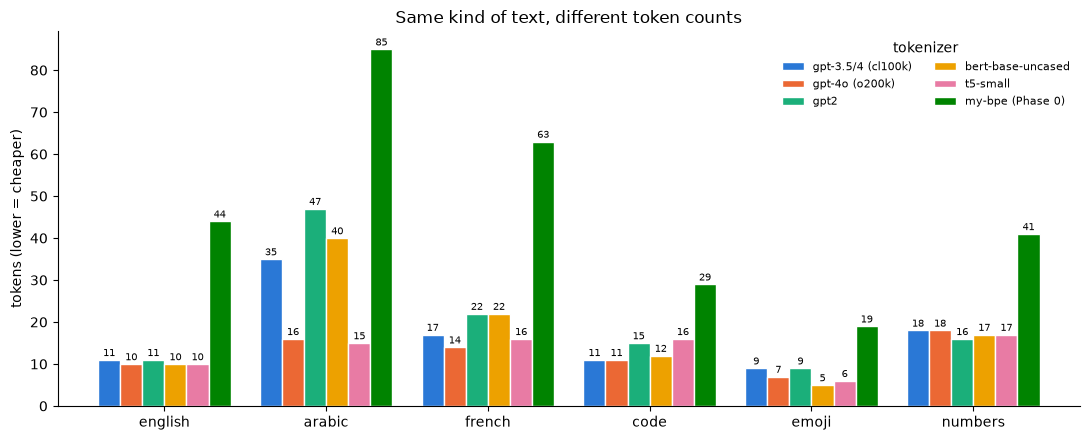

In [6]:
# Colours follow a fixed order per tokenizer (validated colour-blind-safe set); labels are on the bars.
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

ax = tokens_table.plot.bar(figsize=(11, 4.5), width=0.82, color=COLORS[:len(order)], edgecolor="white")
for c in ax.containers:
    ax.bar_label(c, fontsize=7, padding=1)
ax.set_ylabel("tokens (lower = cheaper)"); ax.set_xlabel("")
ax.set_title("Same kind of text, different token counts")
ax.legend(title="tokenizer", fontsize=8, ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 5. What does the same sentence cost in another language?
Ratio = tokens for the sentence in that language / tokens for the English sentence, per tokenizer. A ratio of 2.0 means the same meaning costs **twice** the tokens (twice the price, half the usable context).

In [7]:
ratio = add_ratio_vs(df[df["sample"].isin(["english", "arabic", "french"])], "english")
display(ratio.pivot(index="sample", columns="tokenizer", values="x_vs_english")[order]
        .loc[["english", "french", "arabic"]])

tokenizer,gpt-3.5/4 (cl100k),gpt-4o (o200k),gpt2,bert-base-uncased,t5-small,my-bpe (Phase 0)
sample,,,,,,
english,1.00,1.0,1.00,1.0,1.0,1.00
french,1.55,1.4,2.00,2.2,1.6,1.43
arabic,3.18,1.6,4.27,4.0,1.5,1.93


> **Caution:** this is **one** sentence per language. It shows the effect, but it is not a statistical result. In the final project, use many parallel sentences (for example FLORES-200) and report an average with a range.

## 6. tiktoken pitfalls worth knowing
1. **Names vs models.** `get_encoding("cl100k_base")` and `encoding_for_model("gpt-4o")` are *different* encodings (`gpt-4o` uses `o200k_base`). Always print `encoding.name` so you know which one produced a number.
2. **Special tokens.** By default tiktoken *raises an error* if the text contains something like `<|endoftext|>`, to stop users injecting control tokens. My engine passes `disallowed_special=()` so it is counted as ordinary text.

In [9]:
for model in ["gpt-4", "gpt-4o"]:
    print(f"{model:8} -> {tiktoken.encoding_for_model(model).name}")

enc = tiktoken.get_encoding("cl100k_base")
try:
    enc.encode("hello <|endoftext|>")
except ValueError as e:
    print("\nDefault behaviour:", str(e).splitlines()[0])
print("As plain text :", len(enc.encode("hello <|endoftext|>", disallowed_special=())), "tokens")
print("As special tok:", len(enc.encode("hello <|endoftext|>", allowed_special={"<|endoftext|>"})), "tokens")

gpt-4    -> cl100k_base
gpt-4o   -> o200k_base

Default behaviour: Encountered text corresponding to disallowed special token '<|endoftext|>'.
As plain text : 7 tokens
As special tok: 3 tokens


## 7. My findings (write these yourself)
Look at your own tables and answer in 4-6 sentences. This is the part a recruiter reads.

1. Which tokenizer is most efficient on English? On Arabic? Is it the same one?
2. How many times more tokens does Arabic need than English? Does it change between tokenizers?
3. What happened to the emoji and the numbers? (Look at section 2 for the pieces.)
4. How does my Phase 0 tokenizer compare, and why?
5. One thing that surprised you.

*(your answer here)*

## Key concepts

| Concept | Meaning |
|---|---|
| Tokenizer | Converts text into tokens |
| Token | A piece of text from the vocabulary |
| Token ID | The integer that represents a token |
| BPE | Byte Pair Encoding: merges the most frequent pairs |
| WordPiece | BERT's method; continuation pieces start with `##` |
| Unigram / SentencePiece | Starts with many pieces and prunes; used by T5 and Llama-style models |
| Encoding | The vocabulary + rules a tokenizer uses (for example `cl100k_base`) |
| Decoding | Converts token IDs back into text |
| tiktoken | OpenAI's fast tokenizer library |

`tiktoken` is a **tokenizer, not an embedding model**: it produces integer IDs, not semantic vectors, and it does not understand meaning.